# Chương 4. Phân tích thống kê văn bản (Text EDA)

**Dữ liệu.** [IMDB Dataset of 50K Movie Reviews](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews): 50.000 review phim tiếng Anh, 2 nhãn `positive` / `negative`.

Cuối chương, dữ liệu được khử trùng lặp và chia train/test cố định, dùng chung cho các chương 5–6.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from dmprep import config
from dmprep.data import load_imdb

config.set_seed()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)

RESULTS: dict = {}  # mọi score / p-value của chương này được lưu vào đây

## 4.1 Tổng quan dữ liệu

In [2]:
df = load_imdb()
print("Kích thước:", df.shape)
print(df["sentiment"].value_counts())
n_dup = int(df.duplicated(subset="review").sum())
print("Số review trùng lặp:", n_dup)

RESULTS["n_samples"] = len(df)
RESULTS["n_duplicates"] = n_dup
RESULTS["class_counts"] = df["sentiment"].value_counts().to_dict()
df.head()

Kích thước: (50000, 3)
sentiment
positive    25000
negative    25000
Name: count, dtype: int64
Số review trùng lặp: 418


,review,sentiment,label
0,One of the other reviewers has mentioned that ...,positive,1
1,A wonderful little production. <br /><br />The...,positive,1
2,I thought this was a wonderful way to spend ti...,positive,1
3,Basically there's a family where a little boy ...,negative,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1


**Phân tích kết quả.**

> TODO: cân bằng lớp, trùng lặp, các dấu hiệu nhiễu nhìn thấy được (thẻ HTML `<br />`, ...).

## 4.2 Phân phối độ dài văn bản và kiểm định Mann-Whitney U

Mann-Whitney U là kiểm định phi tham số, $H_0$: phân phối độ dài của hai lớp như nhau. Phù hợp vì độ dài văn bản lệch phải mạnh, không chuẩn.

$$U = n_1 n_2 + \frac{n_1(n_1+1)}{2} - R_1$$

với $R_1$ là tổng hạng của mẫu thứ nhất.

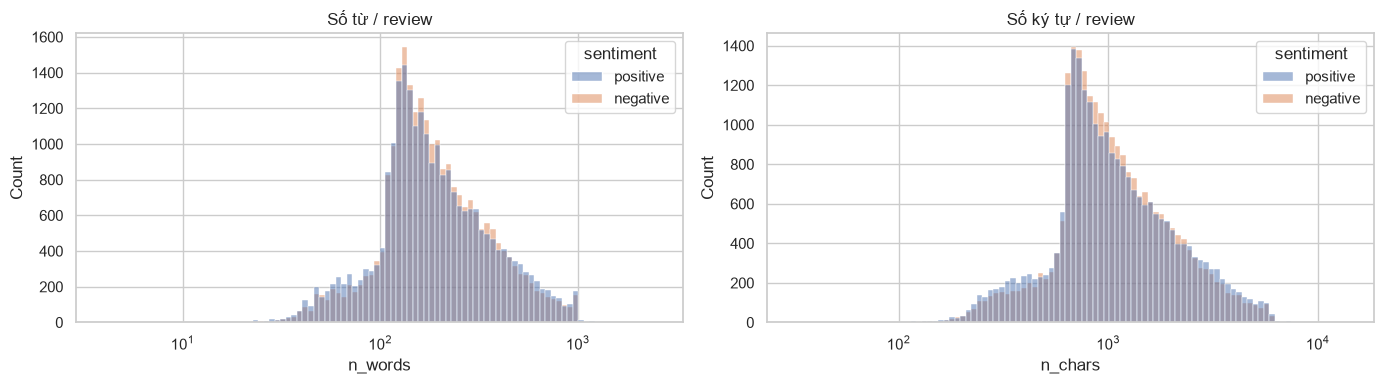

sentiment          negative      positive
n_words count  25000.000000  25000.000000
        mean     229.464560    232.849320
        std      164.947795    177.497046
        min        4.000000     10.000000
        25%      128.000000    125.000000
        50%      174.000000    172.000000
        75%      278.000000    284.000000
        max     1522.000000   2470.000000
n_chars count  25000.000000  25000.000000
        mean    1294.064360   1324.797680
        std      945.892669   1031.492627
        min       32.000000     65.000000
        25%      706.000000    691.000000
        50%      973.000000    968.000000
        75%     1567.250000   1614.000000
        max     8969.000000  13704.000000

In [3]:
df["n_chars"] = df["review"].str.len()
df["n_words"] = df["review"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=df, x="n_words", hue="sentiment", bins=100, log_scale=(True, False), ax=axes[0])
sns.histplot(data=df, x="n_chars", hue="sentiment", bins=100, log_scale=(True, False), ax=axes[1])
axes[0].set_title("Số từ / review"); axes[1].set_title("Số ký tự / review")
plt.tight_layout(); plt.show()

df.groupby("sentiment")[["n_words", "n_chars"]].describe().T

In [4]:
# TODO: kiểm định Mann-Whitney U cho n_words và n_chars giữa hai lớp
# from scipy.stats import mannwhitneyu
# pos, neg = df.query("label == 1"), df.query("label == 0")
# stat, p = mannwhitneyu(pos["n_words"], neg["n_words"], alternative="two-sided")
# RESULTS["mwu_words_p"] = p
# Gợi ý: n rất lớn nên p nhỏ là dễ hiểu; nên báo cáo thêm effect size (ví dụ rank-biserial r).

**Phân tích kết quả.**

> TODO: hai lớp có khác biệt có ý nghĩa thống kê về độ dài không, và khác biệt đó có đáng kể về thực tế không (effect size).

## 4.3 Word cloud, top-50 từ và Type-Token Ratio

$$\text{TTR} = \frac{\text{số từ khác nhau (types)}}{\text{tổng số từ (tokens)}}$$

TTR phụ thuộc mạnh vào độ dài văn bản, nên khi so sánh giữa các lớp cần tính trên cùng số token (hoặc trung bình theo review).

In [5]:
# TODO: word cloud + bảng top-50 từ theo từng lớp, TTR toàn tập và theo lớp
# from wordcloud import WordCloud
# from collections import Counter

**Phân tích kết quả.**

> TODO: từ phổ biến có mang thông tin cảm xúc không, hay toàn stop words / `br`? (gợi ý cho chương 5).

## 4.4 Định luật Zipf

Zipf: tần suất từ thứ hạng $r$ xấp xỉ $f(r) \propto r^{-s}$ với $s \approx 1$. Trên thang log-log là đường thẳng $\log f = c - s\log r$. Ước lượng $s$ bằng hồi quy tuyến tính và đánh giá $R^2$.

In [6]:
# TODO: đếm tần suất từ, vẽ log(rank) – log(freq), fit hồi quy, lưu RESULTS["zipf_s"], RESULTS["zipf_r2"]

**Phân tích kết quả.**

> TODO: mức độ tuân theo Zipf, sai lệch ở phần đầu (từ rất phổ biến) và đuôi (từ hiếm), hệ quả cho độ thưa của biểu diễn.

## 4.5 Chuẩn bị tập train/test cho các chương sau

Khử trùng lặp **trước** khi chia để tránh một review xuất hiện ở cả train và test, sau đó chia phân tầng 80/20 với seed cố định.

In [7]:
from sklearn.model_selection import train_test_split

df_clean = df.drop_duplicates(subset="review").reset_index(drop=True)
_, test_idx = train_test_split(
    df_clean.index, test_size=config.TEST_SIZE, stratify=df_clean["label"], random_state=config.SEED
)
df_clean["split"] = "train"
df_clean.loc[test_idx, "split"] = "test"
df_clean[["review", "sentiment", "label", "split"]].to_parquet(
    config.PROCESSED_DIR / "imdb_split.parquet", index=False
)
print(df_clean["split"].value_counts())
RESULTS["n_after_dedup"] = len(df_clean)

split
train    39665
test      9917
Name: count, dtype: int64


## Lưu kết quả

Toàn bộ con số của chương được ghi ra `data/processed/results/` để chương báo cáo tham chiếu.

In [8]:
config.save_results("04_text_eda", RESULTS)
RESULTS

{'n_samples': 50000,
 'n_duplicates': 418,
 'class_counts': {'positive': 25000, 'negative': 25000},
 'n_after_dedup': 49582}